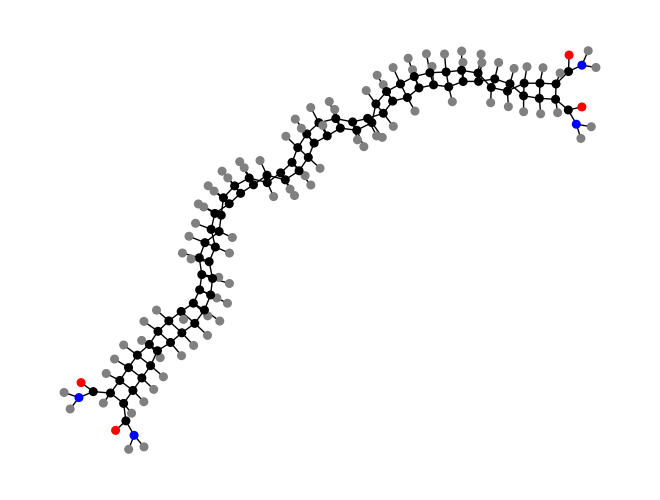

In [1]:
from networkx.generators import ladder_graph
from networkx.drawing.nx_agraph import graphviz_layout

from mupt.mupr.primitives import CompositePrimitive
from mupt.mupr.properties import is_atom
from mupt.interfaces.smiles import primitive_from_smiles


n_segments : int = 40

# map numbers don't matter, as long as they're all the same and nonzero
lexicon = {
    # amino group is just made up; functionalize to your taste
    'corner' : primitive_from_smiles('[NH2]-C(=O)-[CH:1](-[*:1])(-[*:1])'),
    'edge'   : primitive_from_smiles('[CH:1](-[*:1])(-[*:1])(-[*:1])'),
}

LABEL_ATTR : str = 'label'
topology = ladder_graph(n_segments)
for node in topology.nodes:
    if topology.degree(node) == 2:
        topology.nodes[node][LABEL_ATTR] = 'corner'
    elif topology.degree(node) == 3:
        topology.nodes[node][LABEL_ATTR] = 'edge'
    else:
        raise ValueError('Invalid node degree')


molprim = CompositePrimitive()
molprim.populate_from_topology_and_lexicon(
    topology,
    lexicon=lexicon,
    label_attr=LABEL_ATTR,
)

# print(molprim.hierarchy_summary())
xsec = molprim.cross_section(is_atom)
pos = graphviz_layout(xsec, prog='neato')
ax = molprim.visualize_cross_section(xsec, pos=pos, with_labels=False, node_size=30, margins=0.1)